# 05. Кросс-валидация: RR-BLUP vs BRR vs BayesA

Дизайн повторяет Crossa et al. (2013):

- случайные разбиения 70% train / 30% test, 50 повторов;
- метрика — корреляция Пирсона между прогнозом и фактом на тесте
  (predictive ability), плюс RMSE;
- λ для RR-BLUP и приоры для байесовских моделей оцениваются только по
  train внутри каждого разбиения, чтобы не было протечки;
- у гиббс-моделей 8000 итераций, burn-in 2000, thin 5 — ячейка считается
  минут десять, это нормально.

Чего ждать: в Crossa et al. (2010) на этих же данных линейные модели
давали r ≈ 0.4–0.6 в зависимости от среды, а различия между байесовскими
вариантами были малы — урожайность полигенна, и тяжелохвостый приор
BayesA почти не даёт преимущества.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / "gp_models" / "__init__.py").exists():
        sys.path.insert(0, str(cand))
        PROJECT = cand
        break

import gp_models as gpm
from gp_models import data, preprocessing as pp

matplotlib.rcParams["font.family"] = ["Liberation Sans", "Arimo", "DejaVu Sans"]
matplotlib.rcParams["svg.fonttype"] = "none"
FIGDIR = PROJECT / "figures"
FIGDIR.mkdir(exist_ok=True)
%matplotlib inline


In [2]:
w = data.load_wheat()
X, Y = w["X"], w["Y"]

from gp_models import cv
res_rr = {}
for e, name in enumerate(w["env_names"]):
    res_rr[name] = cv.cv_rrblup(Y[:, e], X, lam=None, n_reps=50, seed=1)
    print(f"RR-BLUP {name}: r = {res_rr[name]['r'].mean():.3f} +- {res_rr[name]['r'].std():.3f}")

RR-BLUP 1: r = 0.487 +- 0.045


RR-BLUP 2: r = 0.474 +- 0.061


RR-BLUP 4: r = 0.367 +- 0.068


RR-BLUP 5: r = 0.441 +- 0.050


In [3]:
# гиббс-модели, среда 1 (считается минут десять)
import time
from gp_models import brr, bayesa

y = Y[:, 0]
t0 = time.time()
res_brr = cv.cv_gibbs(y, X, brr.brr_fit, n_reps=50, seed=1,
                      fit_kwargs=dict(n_iter=8000, burn_in=2000, thin=5))
print(f"BRR готово за {(time.time()-t0)/60:.1f} мин")
t0 = time.time()
res_ba = cv.cv_gibbs(y, X, bayesa.bayesa_fit, n_reps=50, seed=1,
                     fit_kwargs=dict(n_iter=8000, burn_in=2000, thin=5))
print(f"BayesA готово за {(time.time()-t0)/60:.1f} мин")


BRR готово за 1.8 мин


BayesA готово за 2.2 мин


  model env  r_mean  r_sd  rmse_mean
RR-BLUP   1   0.487 0.045      0.876
RR-BLUP   2   0.474 0.061      0.878
RR-BLUP   4   0.367 0.068      0.936
RR-BLUP   5   0.441 0.050      0.897
    BRR   1   0.486 0.046      0.877
 BayesA   1   0.488 0.045      0.876


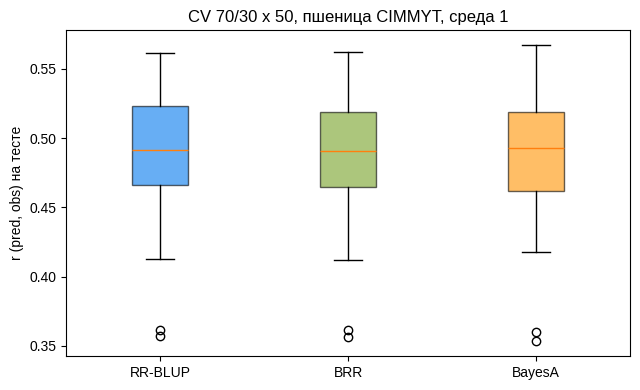

In [4]:
rows = []
for name, r in res_rr.items():
    rows.append(("RR-BLUP", name, r["r"].mean(), r["r"].std(), r["rmse"].mean()))
rows += [("BRR", w["env_names"][0], res_brr["r"].mean(), res_brr["r"].std(), res_brr["rmse"].mean()),
         ("BayesA", w["env_names"][0], res_ba["r"].mean(), res_ba["r"].std(), res_ba["rmse"].mean())]
tab = pd.DataFrame(rows, columns=["model", "env", "r_mean", "r_sd", "rmse_mean"])
print(tab.round(3).to_string(index=False))
(FIGDIR.parent / "results").mkdir(exist_ok=True)
tab.to_csv(FIGDIR.parent / "results" / "cv_results.csv", index=False)
np.savez(FIGDIR.parent / "results" / "cv_per_rep.npz",
         rrblup=res_rr[w["env_names"][0]]["r"], brr=res_brr["r"], bayesa=res_ba["r"])

fig, ax = plt.subplots(figsize=(6.5, 4))
data_box = [res_rr[w["env_names"][0]]["r"], res_brr["r"], res_ba["r"]]
bp = ax.boxplot(data_box, patch_artist=True)
ax.set_xticklabels(["RR-BLUP", "BRR", "BayesA"])
for patch, col in zip(bp["boxes"], ["#0279EE", "#75A025", "#FF9400"]):
    patch.set_facecolor(col); patch.set_alpha(0.6)
ax.set_ylabel("r (pred, obs) на тесте")
ax.set_title(f"CV 70/30 x 50, пшеница CIMMYT, среда {w['env_names'][0]}")
plt.tight_layout()
plt.savefig(FIGDIR / "cv_comparison.png", dpi=150)
plt.savefig(FIGDIR / "cv_comparison.svg")
plt.show()

## Что получилось

- Все три модели дают почти одинаковую точность. Это ожидаемо:
  урожайность полигенна, и тяжёлые хвосты BayesA тут не помогают (в
  Crossa et al. 2010 разница между моделями вылезала в основном на
  признаках с крупными QTL).
- Порядок r совпадает с опубликованным для этих данных (~0.5) — хороший
  знак, значит пайплайн собран правильно.
- Практический вывод: для полигенных признаков можно брать самую дешёвую
  модель (RR-BLUP/GBLUP), а BayesA/BayesB пробовать, когда есть крупные
  QTL или нужен отбор маркеров.
- Дальше (06): то же на кукурузе CIMMYT через GBLUP — сырых маркеров там
  нет, только готовая матрица G.